# A10 -  Árboles de decisión
### Claudio Encarnación (750597)


In [1]:
import pandas as pd
import numpy as np

### DataFrame

In [21]:
GENERO = ['M','M','M','M', 'F','F', 'M','M','M']
EDAD = [21,21,22,20,22,19,27,20,20]
ESTATURA = [1.8,1.76,1.82,1.67,1.75,1.71,1.79,1.66,1.75]
df = pd.DataFrame({'GENERO': GENERO, 'EDAD': EDAD, 'ESTATURA': ESTATURA})

### Varianza de estatura dado que género sea F o M

In [ ]:
varianza_estatura_F = df[df['GENERO'] == 'F']['ESTATURA'].var()
varianza_estatura_M = df[df['GENERO'] == 'M']['ESTATURA'].var()

print("Varianza de estatura para género F:", varianza_estatura_F)
print("Varianza de estatura para género M:", varianza_estatura_M)

Varianza de estatura para género F: 0.0008000000000000014
Varianza de estatura para género M: 0.003933333333333341


### Mejor partición para minimizar la varianza de EDAD en ambos grupos

In [ ]:
mejor_particion = None
mejor_varianza = float('inf')
for edad in sorted(df['EDAD'].unique()):
    grupo_izq = df[df['EDAD'] <= edad]['EDAD']
    grupo_der = df[df['EDAD'] > edad]['EDAD']
    varianza_total = grupo_izq.var() + grupo_der.var()
    if varianza_total < mejor_varianza:
        mejor_varianza = varianza_total
        mejor_particion = edad

print("Mejor partición de EDAD según edades en la recta:", mejor_particion)
print("Varianza grupo izquierdo:", df[df['EDAD'] <= mejor_particion]['EDAD'].var())
print("Varianza grupo derecho:", df[df['EDAD'] > mejor_particion]['EDAD'].var())
print("Varianza de estatura según grupo izquierdo:", df[df['EDAD'] <= mejor_particion]['ESTATURA'].var())
print("Varianza de estatura según grupo derecho:", df[df['EDAD'] > mejor_particion]['ESTATURA'].var())

Mejor partición de EDAD según edades en la recta: 20
Varianza grupo izquierdo: 0.25
Varianza grupo derecho: 6.300000000000001
Varianza de estatura según grupo izquierdo: 0.0016916666666666697
Varianza de estatura según grupo derecho: 0.0008300000000000014


In [16]:
def objetivo(x, df):
    grupo_izq = df[df['EDAD'] <= x]['EDAD']
    grupo_der = df[df['EDAD'] > x]['EDAD']
    varianza_total = grupo_izq.var() + grupo_der.var()
    return varianza_total

print(objetivo(20, df))
print(objetivo(21, df))
print("Varianza estatura según partición 20:", df[df['EDAD'] <= 20]['ESTATURA'].var() + df[df['EDAD'] > 20]['ESTATURA'].var())
print("Varianza estatura grupo izquierdo:", df[df['EDAD'] <= 20]['ESTATURA'].var())
print("Varianza estatura grupo derecho:", df[df['EDAD'] > 20]['ESTATURA'].var())

6.550000000000001
8.9
Varianza estatura según partición 20: 0.002521666666666671
Varianza estatura grupo izquierdo: 0.0016916666666666697
Varianza estatura grupo derecho: 0.0008300000000000014


In [24]:
#Promedio estatura para grupo de Hombres menor o igual a 20
print("Promedio estatura grupo izquierdo hombres:", df[(df['EDAD'] <= 20) & (df['GENERO'] == 'M')]['ESTATURA'].mean())
print("Promedio estatura grupo derecho hombres:", df[(df['EDAD'] > 20) & (df['GENERO'] == 'M')]['ESTATURA'].mean())
print("Promedio estatura grupo izquierdo mujeres:", df[(df['EDAD'] <= 20) & (df['GENERO'] == 'F')]['ESTATURA'].mean())
print("Promedio estatura grupo derecho mujeres:", df[(df['EDAD'] > 20) & (df['GENERO'] == 'F')]['ESTATURA'].mean())

Promedio estatura grupo izquierdo hombres: 1.6933333333333334
Promedio estatura grupo derecho hombres: 1.7925
Promedio estatura grupo izquierdo mujeres: 1.71
Promedio estatura grupo derecho mujeres: 1.75


### Ejercicios con Advertising.csv

In [25]:
df_ad = pd.read_csv("/Users/claudioalejoencarnacionmartinez/Documents/SEMESTRE OTOÑO 2026/LAB APRENDIZAJE ESTADÍSTICO/LABORATORIO-DE-APRENDIZAJE-ESTAD-STICO/Advertising.csv")

In [26]:
df_ad.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


### Regresión lineal simple


In [29]:
from sklearn.linear_model import LinearRegression

X = df_ad.drop(["sales", "Unnamed: 0"], axis=1)
y = df_ad["sales"]

reg = LinearRegression()
reg.fit(X, y)
print(reg.coef_)
print(reg.intercept_)
print("R cuadrado:", reg.score(X, y))

[ 0.04576465  0.18853002 -0.00103749]
2.9388893694594067
R cuadrado: 0.8972106381789522


### Árbol de decisión

R cuadrado: 1.0
Importancia de las características: [0.61906389 0.37743436 0.00350174]
TV: 0.6190638935124588
radio: 0.37743436319763807
newspaper: 0.003501743289903003


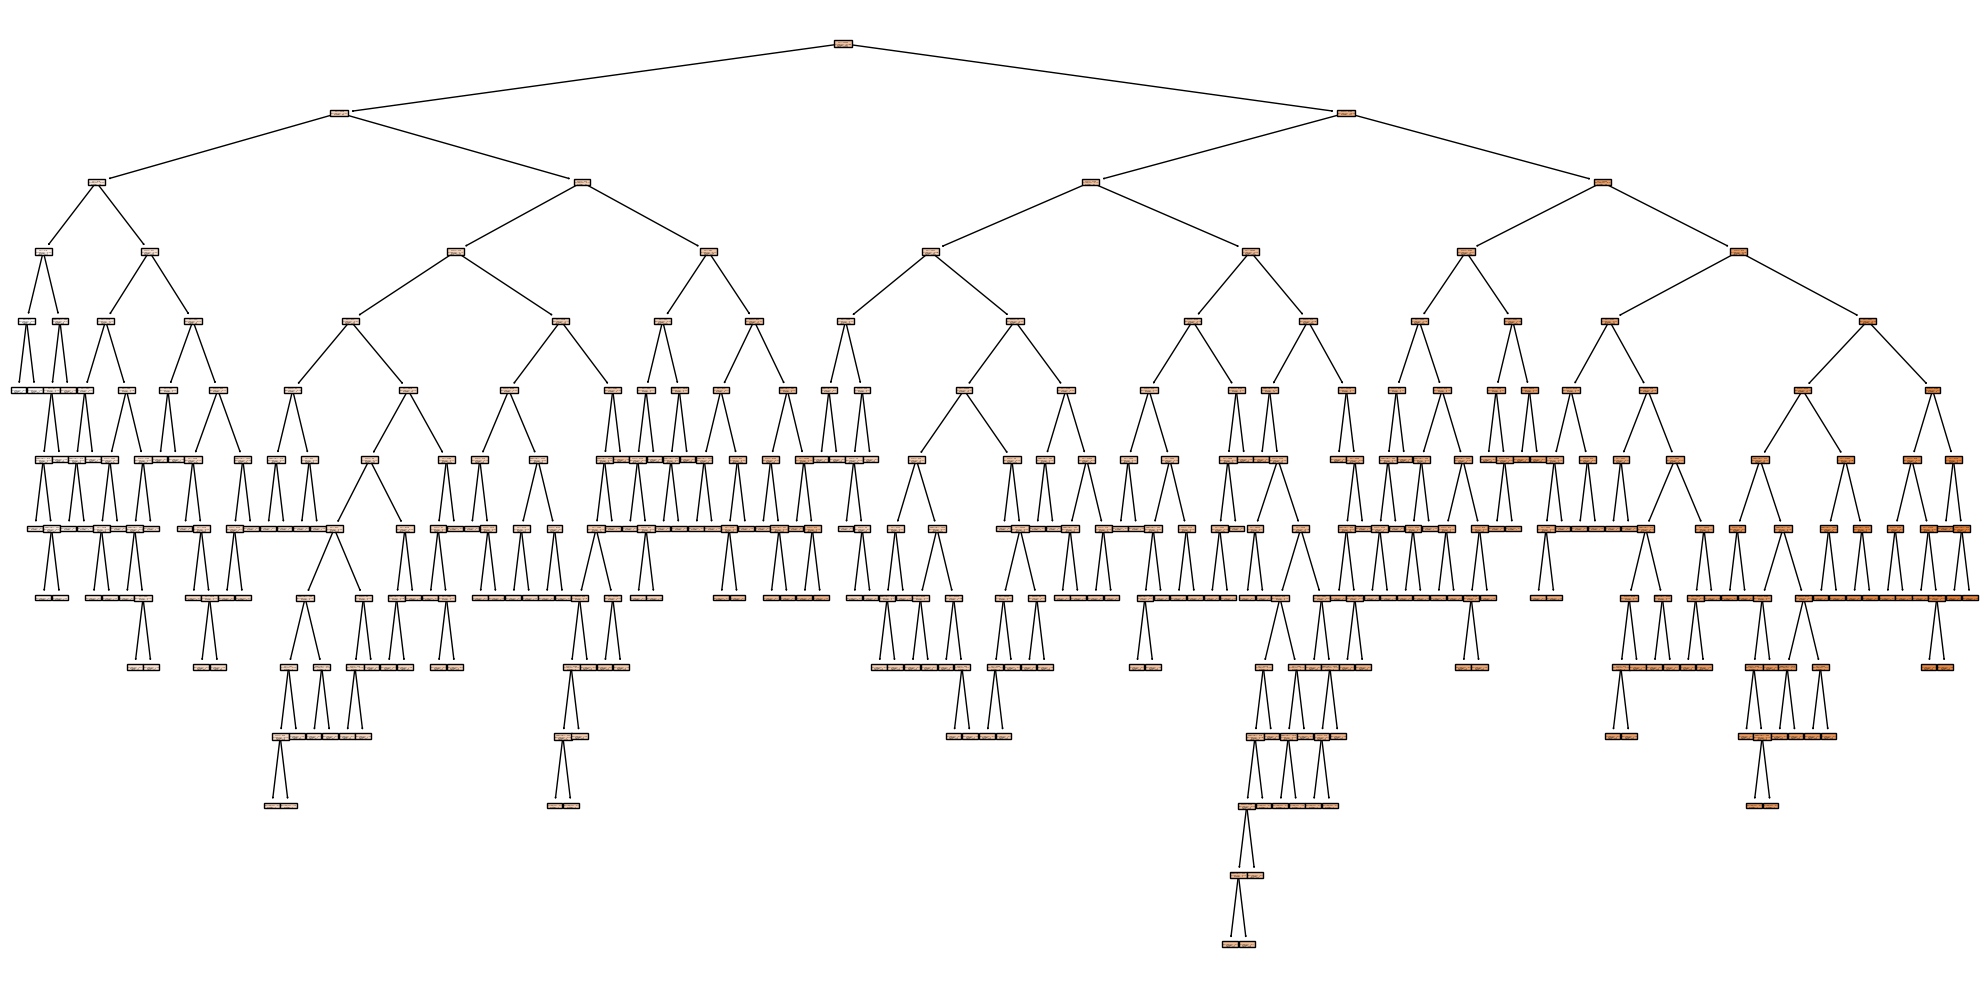

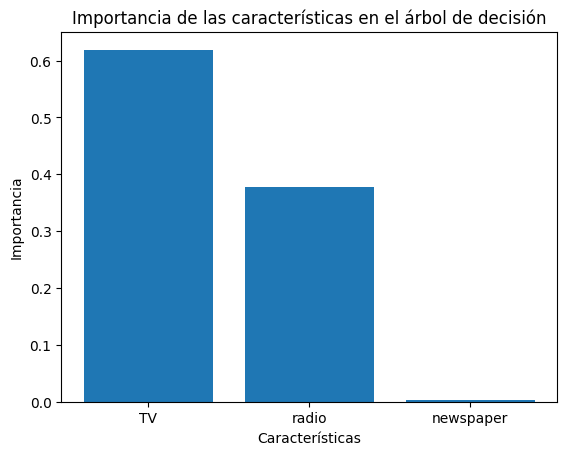

In [32]:
from sklearn.tree import DecisionTreeRegressor

X = df_ad.drop(["sales", "Unnamed: 0"], axis=1)
y = df_ad["sales"]

tree = DecisionTreeRegressor()
tree.fit(X, y)
print("R cuadrado:", tree.score(X, y))
print("Importancia de las características:", tree.feature_importances_)
for feature, importance in zip(X.columns, tree.feature_importances_):
    print(f"{feature}: {importance}")

#Visualización del arbol
from sklearn.tree import plot_tree
plt.figure(figsize=(20,10))
plot_tree(tree, feature_names=X.columns, filled=True)
plt.tight_layout()
plt.show()

# Visualización de la importancia de las características
import matplotlib.pyplot as plt

plt.bar(X.columns, tree.feature_importances_)
plt.xlabel("Características")
plt.ylabel("Importancia")
plt.title("Importancia de las características en el árbol de decisión")
plt.show()

### Cross-validation con train-test 50/50

In [33]:
from sklearn.model_selection import train_test_split

X = df_ad.drop(["sales", "Unnamed: 0"], axis=1)
y = df_ad["sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=67)

tree = DecisionTreeRegressor()
tree.fit(X_train, y_train)
print("R cuadrado en entrenamiento:", tree.score(X_train, y_train))
print("R cuadrado en prueba:", tree.score(X_test, y_test))


R cuadrado en entrenamiento: 1.0
R cuadrado en prueba: 0.9290876528776209


In [34]:
lr = LinearRegression()
lr.fit(X_train, y_train)
print("R cuadrado en entrenamiento:", lr.score(X_train, y_train))
print("R cuadrado en prueba:", lr.score(X_test, y_test))

R cuadrado en entrenamiento: 0.9140145074613925
R cuadrado en prueba: 0.8689022417170023
